# 01 — GTSRB data exploration

This notebook loads the German Traffic Sign Recognition Benchmark (GTSRB), builds the train / validation / test splits used in the rest of the project and describes the data. It also looks at the two classes involved in the backdoor scenario: **Stop** (source, class 14) and **Speed limit 80 km/h** (target, class 5).

All logic lives in `src/`; this notebook only calls functions and displays results. Every parameter comes from `configs/base.yaml`.

## 1. Configuration, seed and environment

We load the configuration, fix every random seed (Python, NumPy, PyTorch, cuDNN) and record the Python and library versions in `results/env_info.json` so the results can be reproduced.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

import pandas as pd

from src.config import load_config, resolve_path
from src.data import (
    GTSRB_CLASS_NAMES,
    class_counts,
    dataset_stats,
    load_gtsrb,
    load_train_groups,
    train_val_split,
)
from src.plots import plot_class_distribution, plot_class_samples, plot_samples_per_class
from src.utils import save_env_info, save_json, set_seed

cfg = load_config()
set_seed(cfg["seed"])
env_info = save_env_info(resolve_path(cfg, "env_info"))
env_info

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/env_info.json


{'python': '3.12.16',
 'platform': 'Linux-7.0.0-43-generic-x86_64-with-glibc2.43',
 'packages': {'torch': '2.5.1',
  'torchvision': '0.20.1',
  'adversarial-robustness-toolbox': '1.18.2',
  'numpy': '1.26.4',
  'scikit-learn': '1.5.2',
  'matplotlib': '3.9.2',
  'pandas': '2.2.3',
  'pyyaml': '6.0.2'},
 'cuda_available': False,
 'device': 'cpu'}

## 2. Loading GTSRB and building the splits

- The data is downloaded with `torchvision.datasets.GTSRB` (official train and test splits).
- Every image is resized to 32x32 RGB. The arrays are cached in `data/processed/` as `uint8`, so later runs skip the download and the resizing.
- `load_gtsrb` returns `float32` arrays of shape (N, 3, 32, 32) with pixel values in **[0, 1]**. Normalisation (mean/std) is **not** applied here: it will be the first layer of the model. This way the backdoor trigger can be added directly in pixel space (a white square is simply the value 1.0), and ART receives raw [0, 1] images.
- **Validation split.** GTSRB training images come in *tracks*: 30 consecutive frames of the same physical sign, filmed while the car approaches it. The track id is in the file name (`<track>_<frame>.ppm`). A random split would put near-identical frames of one track in both train and validation, making validation accuracy over-optimistic. We therefore move **whole tracks**: for each class, `max(1, round(10% × number of tracks))` tracks go to validation. Every class keeps at least one validation track, which is why the validation share per class varies around 10%.
- The **official test set is the clean test set and is never modified**. Later, triggered copies of test images will be created separately for the ASR.

In [2]:
x_train_full, y_train_full, x_test, y_test = load_gtsrb(cfg)
groups = load_train_groups(cfg)
x_train, y_train, x_val, y_val = train_val_split(
    x_train_full, y_train_full, groups, cfg["data"]["val_ratio"], cfg["seed"]
)
print(f"{len(set(groups))} tracks in the official training set")

INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


888 tracks in the official training set


## 3. Dataset characteristics

In [3]:
num_classes = cfg["data"]["num_classes"]
splits = {"train": (x_train, y_train), "val": (x_val, y_val), "test": (x_test, y_test)}
stats = dataset_stats(splits, num_classes)

summary = pd.DataFrame(
    {
        name: {
            "images": s["n_images"],
            "image shape (C, H, W)": tuple(s["image_shape"]),
            "dtype": s["dtype"],
            "pixel range": f"[{s['pixel_min']:.1f}, {s['pixel_max']:.1f}]",
        }
        for name, s in stats["splits"].items()
    }
).T
summary["classes"] = num_classes
summary

,images,"image shape (C, H, W)",dtype,pixel range,classes
train,23880,"(3, 32, 32)",float32,"[0.0, 1.0]",43
val,2760,"(3, 32, 32)",float32,"[0.0, 1.0]",43
test,12630,"(3, 32, 32)",float32,"[0.0, 1.0]",43


## 4. Class distribution

GTSRB is **strongly imbalanced**. In our training split (seed 42), class sizes range from 120 images (Speed limit 20 km/h, Dangerous curve left, Go straight or left) to 1350 (Speed limit 30 and 50 km/h), a ratio of about 11; the test set shows the same pattern (60 to 750 images). The table below the chart recomputes these numbers. Note that every class has a multiple of 30 images: one track is 30 frames.

**Why the poisoning rate is defined relative to the source class.** The attack only poisons Stop images. If the rate were a percentage of the whole training set, the same number (say 1%) would mean very different things depending on how many Stop images exist: for a rare class it could exceed the number of images available, for a frequent class it would be negligible. Expressing it as a percentage of the source class (here 5% of the Stop training images) measures what actually matters for the backdoor (how much of the source class the attacker controls) and stays comparable whichever classes are chosen. This convention is used everywhere in the project.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/class_distribution.png


,smallest class,largest class,max / min
train,120 (Speed limit (20km/h)),1350 (Speed limit (30km/h)),11.2
val,30 (Speed limit (20km/h)),150 (Speed limit (30km/h)),5.0
test,60 (Speed limit (20km/h)),750 (Speed limit (50km/h)),12.5


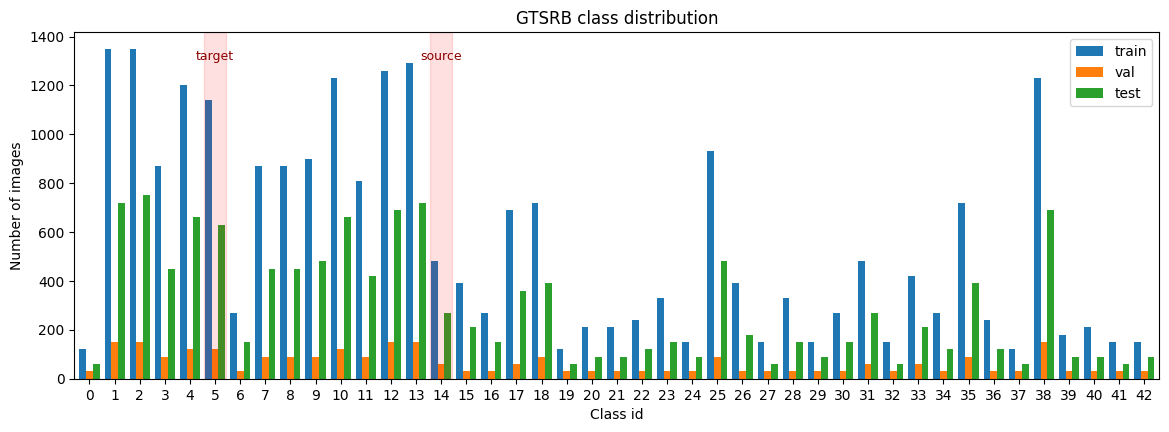

In [4]:
bd = cfg["backdoor"]
source, target = bd["source_class"], bd["target_class"]
counts = {name: class_counts(y, num_classes) for name, (_, y) in splits.items()}

plot_class_distribution(
    counts,
    highlight={source: "source", target: "target"},
    path=resolve_path(cfg, "figures_dir") / "class_distribution.png",
);

imbalance = pd.DataFrame(
    {
        name: {
            "smallest class": f"{c.min()} ({GTSRB_CLASS_NAMES[c.argmin()]})",
            "largest class": f"{c.max()} ({GTSRB_CLASS_NAMES[c.argmax()]})",
            "max / min": round(c.max() / c.min(), 1),
        }
        for name, c in counts.items()
    }
).T
imbalance

## 5. One sample per class

One random training image of each of the 43 classes. The images vary a lot in lighting, blur and resolution.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/samples_per_class.png


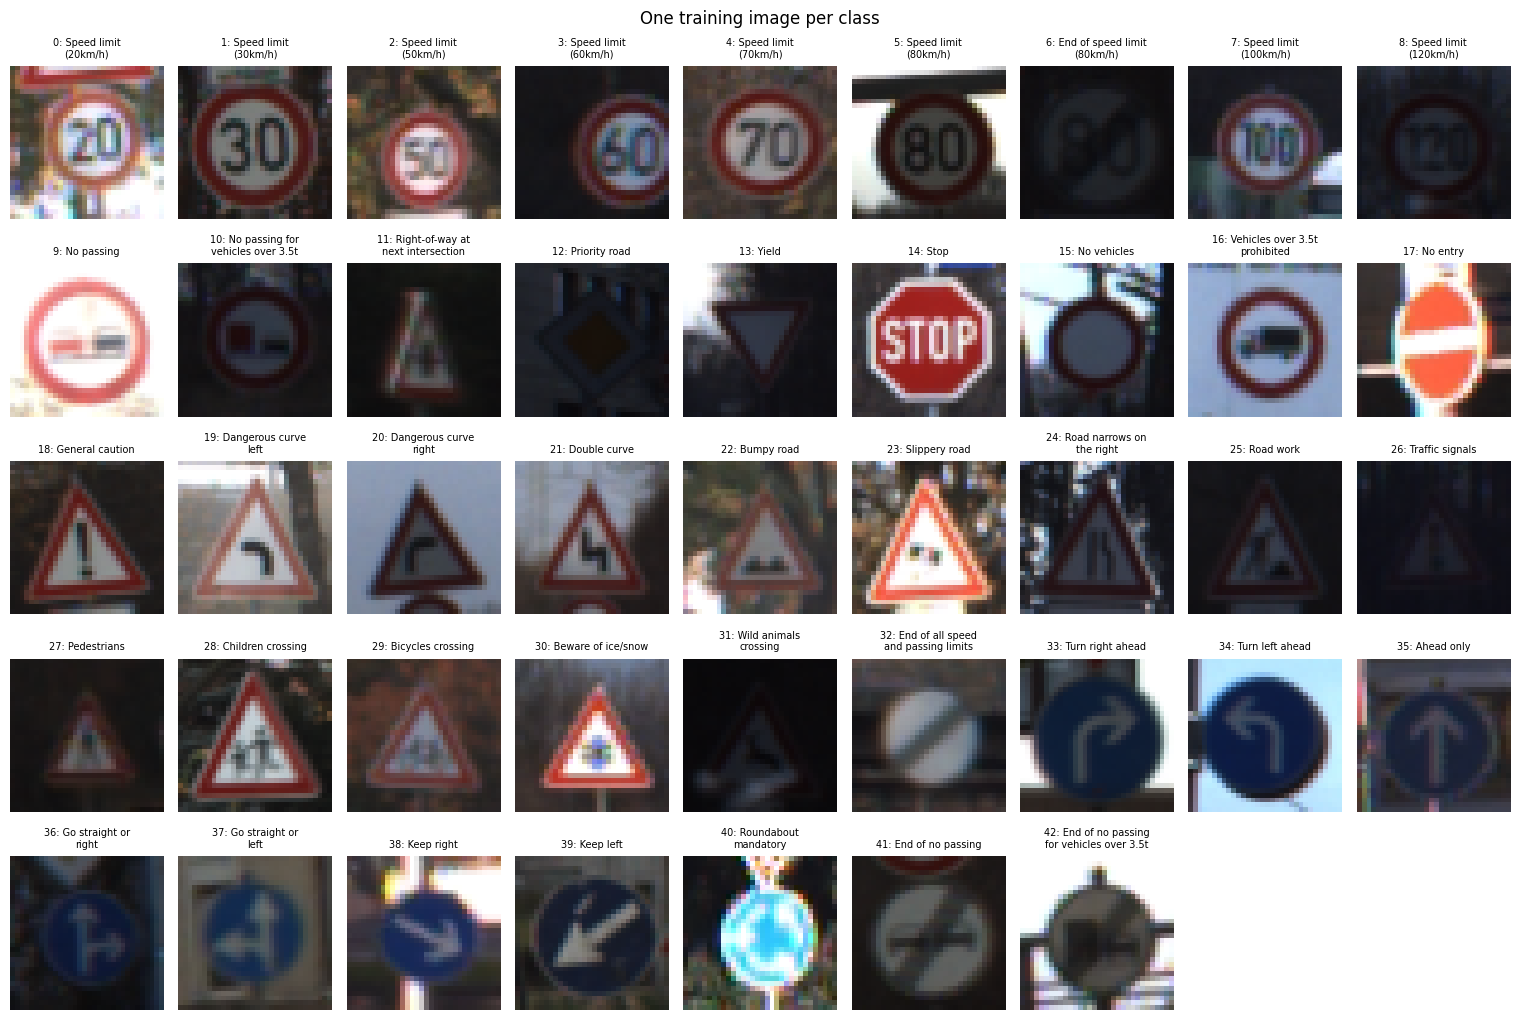

In [5]:
plot_samples_per_class(
    x_train, y_train, GTSRB_CLASS_NAMES,
    path=resolve_path(cfg, "figures_dir") / "samples_per_class.png",
    seed=cfg["seed"],
);

## 6. Source and target classes

The backdoor turns **Stop** signs carrying the trigger (a white 4x4 square in the bottom-right corner) into **Speed limit 80 km/h** predictions. Below: random training images of both classes, their number of images per split, and the number of Stop training images that a 5% poisoning rate represents.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/source_target_samples.png


5% of the 480 Stop training images = 24 poisoned images


,train,val,test
14: Stop,480,60,270
5: Speed limit (80km/h),1140,120,630


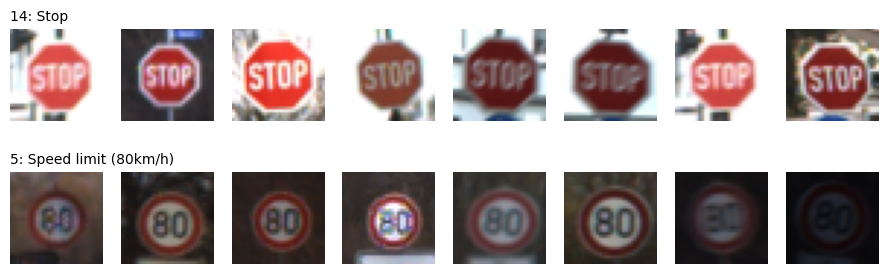

In [6]:
plot_class_samples(
    x_train, y_train, [source, target], n=8, class_names=GTSRB_CLASS_NAMES,
    path=resolve_path(cfg, "figures_dir") / "source_target_samples.png",
    seed=cfg["seed"],
);

n_poison = round(bd["poison_rate"] * counts["train"][source])
source_target = pd.DataFrame(
    {
        f"{c}: {GTSRB_CLASS_NAMES[c]}": {name: int(counts[name][c]) for name in splits}
        for c in (source, target)
    }
).T
print(f"{bd['poison_rate']:.0%} of the {counts['train'][source]} Stop training images = {n_poison} poisoned images")
source_target

## 7. Saving the statistics

Everything shown above is saved to `results/metrics/dataset_stats.json`; the figures are in `results/figures/`.

In [7]:
stats["n_train_tracks"] = int(len(set(groups)))
stats["source_target"] = {
    "source_class": source,
    "target_class": target,
    "source_train_images": int(counts["train"][source]),
    "target_train_images": int(counts["train"][target]),
    "poison_rate_of_source": bd["poison_rate"],
    "n_poisoned_images": n_poison,
}
save_json(stats, resolve_path(cfg, "metrics_dir") / "dataset_stats.json")

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/dataset_stats.json
